# Player Archetypes v3: real Steam players (experiment)

The served model (2.0.0, v2-core, k = 6) was trained on players generated from five designed personas. Here we start
from **real Steam 200k players** and design no playstyles. Real: games played, hours per game, top-game share, and,
from games matched to the Steam Store catalogue, genre diversity and online share. Simulated with **no personas**:
completion and trophies (v2-core rules 1–3 on each player's real hours and games, one population Beta per propensity,
engagement = standardised ln total hours) and, in a variant only, active months.

**Experiment only.** Nothing here changes the served model, the model card, the endpoint, the generators or
`compute_features`. Code: `notebooks/v3_real/v3_real.py` (tests: `test_v3_real.py`). Outputs: `notebooks/v3_real/`.

In [1]:
REPO_URL = "https://github.com/aljoharas/2026-GP1-Group8.git"
REPO_BRANCH = "feature/archetype-v3-real"
import sys
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_DIR = Path("/content/2026-GP1-Group8")
    if not REPO_DIR.exists():
        !git clone -q -b {REPO_BRANCH} {REPO_URL} {REPO_DIR}
else:
    REPO_DIR = Path.cwd()
    while not (REPO_DIR / "models").exists():
        REPO_DIR = REPO_DIR.parent
# data/ is gitignored. Needs data/steam-200k.csv, data/steam_catalogue.csv and
# data/steam_catalogue_matches.csv (the last two are written by notebooks/archetypes_training_v2.ipynb).
DATA = REPO_DIR / "data"
OUT = REPO_DIR / "notebooks" / "v3_real"
FIG, TAB = OUT / "figures", OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(OUT)); sys.path.insert(0, str(REPO_DIR / "notebooks"))
print(REPO_DIR, [p.name for p in DATA.glob("*.csv")])

/Users/aljoharaalsultan/Development/2026-GP1-Group8 ['steam_catalogue.csv', 'steam_catalogue_matches.csv', 'steam.csv', 'steam_game_hours.csv', 'steam-200k.csv', 'steam_library_sizes.csv']


In [2]:
import json, itertools
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from scipy.stats import spearmanr
import v3_real as V

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
V3C, V2C = SERIES[0], SERIES[1]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()
def table(df, name, digits=4):
    df.round(digits).to_csv(TAB / f"{name}.csv"); return df
R = {}

## 1. Real player base

In [3]:
plays = V.sim.load_steam_plays(str(DATA / "steam-200k.csv"))
cat = V.load_catalogue(DATA / "steam_catalogue.csv")
matches = pd.read_csv(DATA / "steam_catalogue_matches.csv")
n_before = int((plays.groupby("user_id")["game"].size() >= V.MIN_GAMES).sum())
games, ANON, CAP = V.build_base(plays, cat, matches)
MEDIAN_LEN = V.median_typical_length(cat)
R["base"] = V.base_summary(games, n_before, CAP)
R["median_length"] = MEDIAN_LEN
del plays["user_id"]   # Steam user ids are not used past this point; outputs use P0001...
pd.Series(R["base"]).to_frame("value")

,value
users with >= 5 played titles,2436.000000
users kept (>= 5 games after merging same-game titles),2408.000000
games (player x game),57210.000000
games per user: median,12.000000
games per user: p25,7.000000
games per user: p75,25.000000
games per user: p90,57.000000
share of games matched,0.718266
share of hours matched,0.795307
users with < 50% of hours matched,265.000000


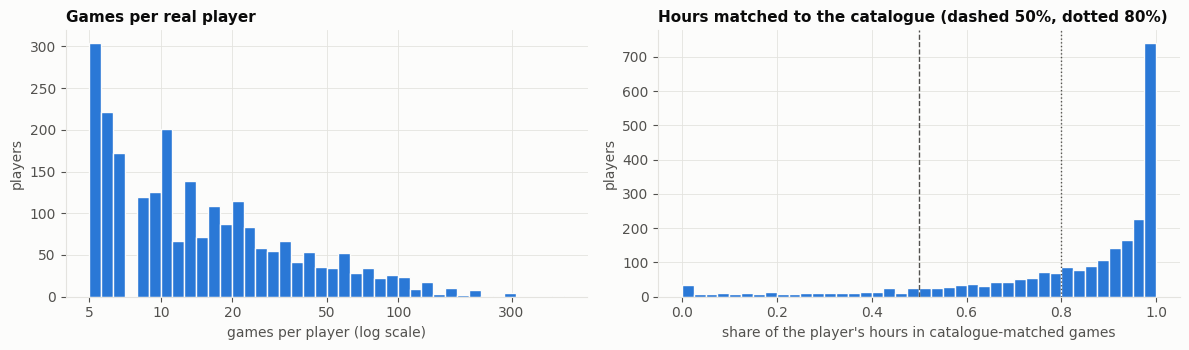

In [4]:
ms = V.matched_share(games)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
n = games.groupby("pid").size()
a1.hist(np.log10(n), bins=40, color=V3C, edgecolor=SURFACE)
a1.set_xticks(np.log10([5, 10, 20, 50, 100, 300]), [5, 10, 20, 50, 100, 300])
a1.set_xlabel("games per player (log scale)"); a1.set_ylabel("players"); a1.set_title("Games per real player")
a2.hist(ms, bins=40, color=V3C, edgecolor=SURFACE)
a2.axvline(0.5, color=INK2, ls="--", lw=1); a2.axvline(0.8, color=INK2, ls=":", lw=1)
a2.set_xlabel("share of the player's hours in catalogue-matched games"); a2.set_ylabel("players")
a2.set_title("Hours matched to the catalogue (dashed 50%, dotted 80%)")
fig.tight_layout(); save(fig, "01_base")

## 2. Features: real where possible

Completion and trophy propensities are drawn per player from **one population Beta** each, matching the mean and
variance of the equal-weight mixture of the five v2 persona Betas. Engagement z = standardised ln(total real hours),
adding +0.3·z to both logits (v2's rule 4 strength). Rules 1–3 as in v2-core (M = 0.6, E = 2, 2% for
multiplayer-only). Unmatched games (and matched games without a SteamSpy length) use the catalogue's median typical
length for rule 1 and have no trophy list. Main run: 7 features (no activity). Variant: + activity with
months ~ Uniform{6..12}.

In [5]:
betas = pd.DataFrame([
    {"propensity": "completion", "a": V.COMPLETION_BETA[0], "b": V.COMPLETION_BETA[1], "mean": V.COMPLETION_BETA[2], "variance": V.COMPLETION_BETA[3]},
    {"propensity": "trophy", "a": V.TROPHY_BETA[0], "b": V.TROPHY_BETA[1], "mean": V.TROPHY_BETA[2], "variance": V.TROPHY_BETA[3]},
]).set_index("propensity")
R["betas"] = betas.to_dict("index")
MAIN, ACT = V.SimConfig(), V.SimConfig(activity=True)
runs = {s: V.run(games, s, MAIN, MEDIAN_LEN) for s in V.SEEDS}           # (games, players, X)
runs_act = {s: V.run(games, s, ACT, MEDIAN_LEN) for s in V.SEEDS}
X42 = runs[42][2]
app_online = V.online_share_app_rule(runs[42][0])
diff = (X42["online_share"] - app_online.reindex(X42.index)).dropna()
R["online_share_rule"] = {"median_matched_only": float(X42["online_share"].median()), "median_app_rule": float(app_online.median()),
                          "mean_difference": float(diff.mean()), "players_without_matched_hours": int(X42["online_share"].isna().sum())}
R["missing_main"] = X42.isna().sum().to_dict()
display(table(betas, "propensity_betas"))
print("online share, matched games only vs app rule (unmatched counted offline):", R["online_share_rule"])
print("missing (imputed with the training mean):", R["missing_main"])

,a,b,mean,variance
propensity,,,,
completion,1.661293,1.836031,0.475018,0.05545
trophy,1.393795,2.961814,0.320000,0.04063


online share, matched games only vs app rule (unmatched counted offline): {'median_matched_only': 0.916758849557522, 'median_app_rule': 0.7367692023699743, 'mean_difference': 0.12671981843801022, 'players_without_matched_hours': 13}
missing (imputed with the training mean): {'completion_rate': 0, 'trophy_rate': 45, 'genre_diversity': 13, 'log_hours_per_game': 0, 'top_game_share': 0, 'online_share': 13, 'log_games_played': 0}


## 3. Plausibility checks (before clustering)

In [6]:
checks = V.plausibility(runs[42][0])
R["plausibility"] = checks.to_dict("records")
display(table(checks.set_index("check"), "plausibility"))
c = checks.set_index("check")["count"]
o = checks.set_index("check")["out of"]
assert c["100% trophies on an unfinished game"] == 0
assert c["100% trophies with r < 1 + E (3)"] == 0
assert c["  of which not multiplayer-only (rule 1)"] <= 0.001 * o["  of which not multiplayer-only (rule 1)"]
mp_rate = c["completed multiplayer-only games"] / o["completed multiplayer-only games"]
assert abs(mp_rate - 0.02) < 4 * np.sqrt(0.02 * 0.98 / o["completed multiplayer-only games"]), mp_rate
print(f"checks pass; multiplayer-only completion rate {mp_rate:.2%}")

,count,out of
check,,
completed with r < 0.3 (all games),67,17111
of which multiplayer-only (rule 3's flat 2%),63,2826
of which not multiplayer-only (rule 1),4,14285
100% trophies on an unfinished game,0,23816
100% trophies with r < 1 + E (3),0,23773
completed multiplayer-only games,187,8838
completed games overall,12541,57210


checks pass; multiplayer-only completion rate 2.12%


In [7]:
# v2-core training players (the served model's population), features only; cached
v2_path = TAB / "v2core_features_seed42.csv"
if v2_path.exists():
    X2 = pd.read_csv(v2_path)
else:
    import archetype_v2_lib as L
    _, cal2, CAT2, _, _ = L.load_inputs(DATA / "steam-200k.csv", DATA / "steam_catalogue.csv")
    P2 = L.sim2.generate_players(cal2, CAT2, 500, L.MIX_SHARE, 42, L.sim2.rules_variant(rule5_trophy_hunters={"on": False}))
    X2 = L.features(P2)
    X2.to_csv(v2_path, index=False)
X2 = X2[V.FEATURES_ACTIVITY]
X3a = runs_act[42][2]
def spearman(X):
    return pd.DataFrame(spearmanr(X, nan_policy="omit").correlation, index=X.columns, columns=X.columns)
s3, s2 = spearman(X3a), spearman(X2)
pairs = list(itertools.combinations(V.FEATURES_ACTIVITY, 2))
corr = pd.DataFrame([{"pair": f"{a} ↔ {b}", "v3 (real)": s3.loc[a, b], "v2-core": s2.loc[a, b]} for a, b in pairs]).set_index("pair")
corr["Δ"] = corr["v3 (real)"] - corr["v2-core"]
R["spearman"] = corr.reset_index().to_dict("records")
table(corr, "spearman_v3_v2core").round(2)

,v3 (real),v2-core,Δ
pair,,,
completion_rate ↔ trophy_rate,0.30,0.66,-0.35
completion_rate ↔ genre_diversity,0.07,0.05,0.01
completion_rate ↔ log_hours_per_game,0.43,0.59,-0.16
completion_rate ↔ top_game_share,-0.26,-0.05,-0.21
completion_rate ↔ log_activity,0.36,0.31,0.05
completion_rate ↔ online_share,-0.22,0.02,-0.24
completion_rate ↔ log_games_played,0.23,0.04,0.19
trophy_rate ↔ genre_diversity,0.02,0.05,-0.03
trophy_rate ↔ log_hours_per_game,0.37,0.64,-0.27


mean    p10    p25    p50    p75    p90
feature            population                                          
completion_rate    v3 (real)   0.193  0.000  0.045  0.167  0.286  0.429
                   v2-core     0.211  0.000  0.000  0.167  0.333  0.533
trophy_rate        v3 (real)   0.140  0.019  0.048  0.110  0.204  0.305
                   v2-core     0.145  0.028  0.054  0.100  0.194  0.337
genre_diversity    v3 (real)   0.572  0.312  0.427  0.591  0.725  0.811
                   v2-core     0.774  0.519  0.673  0.814  0.913  0.984
log_hours_per_game v3 (real)   2.127  1.199  1.587  2.062  2.579  3.100
                   v2-core     1.690  0.874  1.134  1.587  2.180  2.665
top_game_share     v3 (real)   0.490  0.207  0.311  0.463  0.654  0.842
                   v2-core     0.515  0.233  0.321  0.451  0.683  0.945
log_activity       v3 (real)   3.806  1.703  2.795  4.058  4.902  5.454
                   v2-core     2.541  1.309  1.769  2.424  3.173  3.994
online_share       v3 (real)   0.775  0.282  0.639  0.917  0.998  1.000
                   v2-core     0.430  0.001  0.070  0.376  0.778  0.964
log_games_played   v3 (real)   2.684  1.609  1.946  2.485  3.219  4.043
                   v2-core     2.147  1.609  1.792  2.079  2.398  2.833

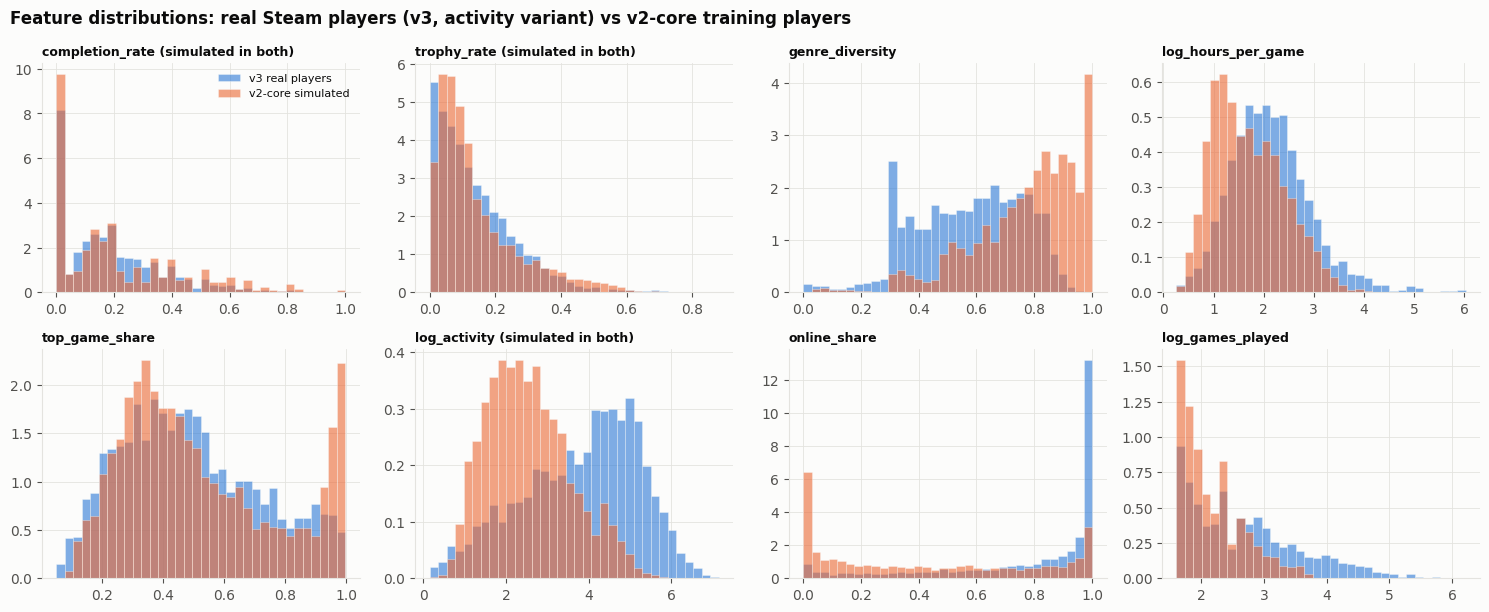

In [8]:
q = [0.1, 0.25, 0.5, 0.75, 0.9]
rows = []
for f in V.FEATURES_ACTIVITY:
    for lab, X in (("v3 (real)", X3a), ("v2-core", X2)):
        x = X[f].dropna()
        rows.append({"feature": f, "population": lab, "mean": x.mean(), **{f"p{int(p*100)}": x.quantile(p) for p in q}})
dist = pd.DataFrame(rows).set_index(["feature", "population"])
R["distributions"] = dist.reset_index().to_dict("records")
display(table(dist, "feature_distributions_v3_v2core").round(3))
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for ax, f in zip(axes.flat, V.FEATURES_ACTIVITY):
    lo = min(X3a[f].min(), X2[f].min()); hi = max(X3a[f].max(), X2[f].max())
    bins = np.linspace(lo, hi, 35)
    ax.hist(X3a[f].dropna(), bins=bins, density=True, alpha=0.6, color=V3C, label="v3 real players", edgecolor=SURFACE, lw=0.4)
    ax.hist(X2[f].dropna(), bins=bins, density=True, alpha=0.6, color=V2C, label="v2-core simulated", edgecolor=SURFACE, lw=0.4)
    ax.set_title(f + (" (simulated in both)" if f in ("completion_rate", "trophy_rate", "log_activity") else ""), fontsize=9)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Feature distributions: real Steam players (v3, activity variant) vs v2-core training players", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "02_distributions_v3_v2core")

## 4. Cluster

StandardScaler → `KMeans(n_init=20, random_state=42)`, k = 2..8, on the main run (7 features) for seeds 42 and 0–4.
The real features are identical across seeds; only completion and trophies are re-drawn. **No final k is picked
here.**

In [9]:
KS = list(range(2, 9))
sweeps = {s: V.sweep(runs[s][2], KS) for s in V.SEEDS}     # (fits, sil, inertia)
sil = pd.DataFrame({f"seed {s}": sweeps[s][1] for s in V.SEEDS}).rename_axis("k")
sil["mean"] = sil.mean(axis=1)
best_mean = int(sil["mean"].idxmax())
flag_mean = V.near_ties(sil["mean"].to_dict())
flags_seed = {s: V.near_ties(sweeps[s][1]) for s in V.SEEDS}
sil["within 0.01 of best (mean)"] = ["yes" if k in flag_mean else "" for k in sil.index]
R["silhouette"] = sil.drop(columns="within 0.01 of best (mean)").to_dict()
R["flags"] = {"mean": flag_mean, "best_mean": best_mean, "per_seed": {str(s): v for s, v in flags_seed.items()}}
print("best k by mean silhouette:", best_mean, "| within 0.01 of it:", flag_mean)
print("within 0.01 of each seed's best:", flags_seed)
table(sil, "silhouette_by_k_seed").round(3)

best k by mean silhouette: 4 | within 0.01 of it: [4]
within 0.01 of each seed's best: {42: [4], 0: [4], 1: [2, 4], 2: [4], 3: [2, 4], 4: [2, 4]}


,seed 42,seed 0,seed 1,seed 2,seed 3,seed 4,mean,within 0.01 of best (mean)
k,,,,,,,,
2,0.208,0.203,0.203,0.204,0.207,0.204,0.205,
3,0.206,0.204,0.196,0.202,0.202,0.200,0.202,
4,0.219,0.217,0.212,0.216,0.214,0.212,0.215,yes
5,0.182,0.178,0.176,0.182,0.181,0.179,0.180,
6,0.183,0.178,0.183,0.189,0.187,0.188,0.185,
7,0.166,0.165,0.169,0.177,0.174,0.176,0.171,
8,0.151,0.161,0.164,0.157,0.158,0.174,0.161,


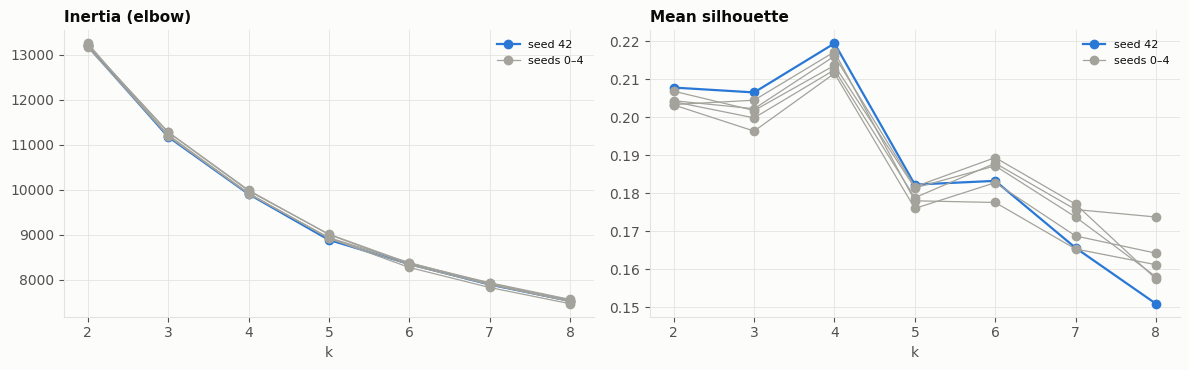

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
for i, s in enumerate(V.SEEDS):
    a1.plot(KS, [sweeps[s][2][k] for k in KS], marker="o", lw=1.6 if s == 42 else 0.9,
            color=V3C if s == 42 else "#a3a29b", label="seed 42" if s == 42 else ("seeds 0–4" if s == 0 else None))
    a2.plot(KS, [sweeps[s][1][k] for k in KS], marker="o", lw=1.6 if s == 42 else 0.9,
            color=V3C if s == 42 else "#a3a29b", label="seed 42" if s == 42 else ("seeds 0–4" if s == 0 else None))
a1.set_title("Inertia (elbow)"); a2.set_title("Mean silhouette")
for a in (a1, a2):
    a.set_xticks(KS); a.set_xlabel("k"); a.legend(fontsize=8)
fig.tight_layout(); save(fig, "03_choose_k")

In [11]:
SHOW_K = sorted(set([3, 6, best_mean] + flag_mean))
stab, s2s = {}, {}
for k in SHOW_K:
    stab[k] = V.restart_stability(runs[42][2], k)
    lab42 = sweeps[42][0][k].labels
    s2s[k] = {s: float(adjusted_rand_score(lab42, sweeps[s][0][k].labels)) for s in V.SEEDS if s != 42}
st = pd.DataFrame({k: {"restart ARI mean (10 restarts, seed 42)": stab[k]["mean_pairwise"],
                       "restart ARI min": stab[k]["min_pairwise"],
                       "seed-to-seed ARI min (vs seed 42)": min(s2s[k].values()),
                       "seed-to-seed ARI max": max(s2s[k].values())} for k in SHOW_K}).T.rename_axis("k")
R["stability"] = {int(k): {**stab[k], "seed_to_seed": {str(s): v for s, v in s2s[k].items()}} for k in SHOW_K}
table(st, "stability").round(3)

,"restart ARI mean (10 restarts, seed 42)",restart ARI min,seed-to-seed ARI min (vs seed 42),seed-to-seed ARI max
k,,,,
3,0.962,0.931,0.594,0.627
4,0.987,0.974,0.617,0.687
6,0.931,0.854,0.539,0.595


In [12]:
R["centres"] = {}
for k in SHOW_K:
    f = sweeps[42][0][k]
    c = f.centres_original()
    c["players"] = np.bincount(f.labels, minlength=k)
    c["share"] = c["players"] / len(f.labels)
    R["centres"][int(k)] = c.to_dict("records")
    print(f"k = {k} (seed 42), centres in original units")
    display(table(c, f"centres_k{k}").round(3))

k = 3 (seed 42), centres in original units


,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,online_share,log_games_played,players,share
0,0.196,0.140,0.721,1.938,0.307,0.687,3.438,921,0.382
1,0.094,0.098,0.480,1.873,0.660,0.878,2.175,1031,0.428
2,0.407,0.236,0.480,3.085,0.473,0.719,2.318,456,0.189


k = 4 (seed 42), centres in original units


,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,online_share,log_games_played,players,share
0,0.101,0.105,0.482,1.938,0.666,0.959,2.190,945,0.392
1,0.204,0.147,0.733,1.975,0.300,0.763,3.584,787,0.327
2,0.171,0.093,0.524,1.846,0.470,0.235,2.305,323,0.134
3,0.432,0.261,0.499,3.232,0.460,0.803,2.351,353,0.147


k = 6 (seed 42), centres in original units


,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,online_share,log_games_played,players,share
0,0.172,0.097,0.503,1.852,0.491,0.198,2.284,274,0.114
1,0.507,0.180,0.458,3.487,0.466,0.784,2.137,212,0.088
2,0.247,0.144,0.752,1.967,0.235,0.659,4.038,429,0.178
3,0.105,0.080,0.658,1.703,0.450,0.897,2.536,618,0.257
4,0.257,0.329,0.617,2.576,0.422,0.830,2.955,289,0.120
5,0.108,0.113,0.401,2.108,0.759,0.970,2.102,586,0.243


## 5. Compare with the served model (2.0.0, v2-core)

Matching uses the 7 shared features, in the **served model's SD units** (its scaler). A v2-core archetype counts as
*appearing* among real players when its Hungarian-matched v3 cluster is also its mutual nearest centre **and** lies
closer than half the distance from that archetype to its nearest other v2-core archetype (my criterion, stated
before reading the result).

In [13]:
SERVED = json.loads((REPO_DIR / "models" / "archetype_model.json").read_text())
names = [c["name"] for c in SERVED["clusters"]]
smean, sscale = np.array(SERVED["scaler"]["mean"]), np.array(SERVED["scaler"]["scale"])
i7 = [V.FEATURES_ACTIVITY.index(f) for f in V.FEATURES_MAIN]
S7 = np.array([c["centre_scaled"] for c in SERVED["clusters"]])[:, i7]
dS = np.linalg.norm(S7[:, None] - S7[None], axis=2); np.fill_diagonal(dS, np.inf)
half_gap = dS.min(axis=1) / 2
def in_served_units(fit):
    return (fit.centres_original()[V.FEATURES_MAIN].to_numpy() - smean[i7]) / sscale[i7]
def compare_to_served(k):
    fit = sweeps[42][0][k]
    C = in_served_units(fit)
    mapping, d = V.hungarian(S7, C)
    rows = []
    for i, nm in enumerate(names):
        j = mapping.get(i)
        if j is None:
            rows.append({"v2-core archetype": nm, "v3 cluster": None, "distance (SD)": None, "mutual nearest": False,
                         "half gap": half_gap[i], "appears": False}); continue
        mutual = d[:, j].argmin() == i and d[i].argmin() == j
        rows.append({"v2-core archetype": nm, "v3 cluster": j, "distance (SD)": d[i, j], "mutual nearest": bool(mutual),
                     "half gap": half_gap[i], "appears": bool(mutual and d[i, j] < half_gap[i])})
    unmatched = [j for j in range(k) if j not in mapping.values()]
    nearest = {j: names[int(d[:, j].argmin())] for j in range(k)}
    return pd.DataFrame(rows).set_index("v2-core archetype"), unmatched, nearest, d
R["match"] = {}
for k in sorted(set([6, best_mean])):
    tab, unmatched, nearest, d = compare_to_served(k)
    R["match"][int(k)] = {"table": tab.reset_index().to_dict("records"), "unmatched_v3_clusters": unmatched,
                          "nearest_served_for_each_v3_cluster": nearest}
    print(f"k = {k}: unmatched v3 clusters {unmatched}; each v3 cluster's nearest served archetype {nearest}")
    display(table(tab, f"match_to_served_k{k}").round(3))
    display(table(pd.DataFrame(d, index=names, columns=[f"v3 c{j}" for j in range(k)]), f"distance_served_v3_k{k}").round(2))

k = 4: unmatched v3 clusters []; each v3 cluster's nearest served archetype {0: 'The Main', 1: 'Explorer', 2: 'Devotee', 3: 'Competitor'}


,v3 cluster,distance (SD),mutual nearest,half gap,appears
v2-core archetype,,,,,
Devotee,2.0,1.950,True,1.290,False
Competitor,3.0,2.388,True,1.262,False
Explorer,1.0,2.450,True,1.193,False
Casual,NaN,NaN,False,1.193,False
The Main,0.0,1.021,True,1.290,True
Completionist,NaN,NaN,False,1.262,False


,v3 c0,v3 c1,v3 c2,v3 c3
Devotee,2.84,4.75,1.95,4.04
Competitor,2.55,3.14,2.61,2.39
Explorer,3.85,2.45,2.87,4.67
Casual,2.98,4.05,2.17,4.47
The Main,1.02,4.26,2.68,3.29
Completionist,4.16,4.20,3.41,2.99


k = 6: unmatched v3 clusters []; each v3 cluster's nearest served archetype {0: 'Devotee', 1: 'Competitor', 2: 'Explorer', 3: 'Competitor', 4: 'Competitor', 5: 'The Main'}


,v3 cluster,distance (SD),mutual nearest,half gap,appears
v2-core archetype,,,,,
Devotee,0,1.838,True,1.290,False
Competitor,1,2.722,False,1.262,False
Explorer,2,2.944,False,1.193,False
Casual,3,2.401,False,1.193,False
The Main,5,0.970,True,1.290,True
Completionist,4,3.020,False,1.262,False


,v3 c0,v3 c1,v3 c2,v3 c3,v3 c4,v3 c5
Devotee,1.84,4.13,5.49,3.33,4.24,2.86
Competitor,2.73,2.72,4.04,2.05,2.40,2.97
Explorer,3.02,5.11,2.94,2.51,3.62,4.45
Casual,2.26,4.72,4.85,2.40,4.14,3.46
The Main,2.70,3.45,5.21,2.23,3.48,0.97
Completionist,3.45,3.45,4.80,3.88,3.02,4.42


In [14]:
# Real Steam players assigned with the SERVED 2.0.0 model (activity variant: 8 features)
imp = pd.Series({**SERVED["imputation"], "online_share": float(smean[V.FEATURES_ACTIVITY.index("online_share")])})
Xs = X3a[V.FEATURES_ACTIVITY].fillna(imp)
Zs = (Xs.to_numpy() - smean) / sscale
C8 = np.array([c["centre_scaled"] for c in SERVED["clusters"]])
served_lab = np.argmin(((Zs[:, None] - C8[None]) ** 2).sum(axis=2), axis=1)
spread = pd.Series([names[i] for i in served_lab]).value_counts().reindex(names, fill_value=0)
spread = pd.DataFrame({"players": spread, "share": spread / spread.sum(),
                       "training share (v2-core)": [c["training_share"] for c in SERVED["clusters"]]})
ari_served_v3 = float(adjusted_rand_score(served_lab, sweeps[42][0][6].labels))
R["served_assignment"] = {"spread": spread.to_dict("index"), "ari_vs_v3_k6": ari_served_v3}
print(f"ARI(served 2.0.0 assignment, v3 own k = 6 clustering) on the same {len(Xs)} players: {ari_served_v3:.3f}")
display(pd.crosstab(pd.Series([names[i] for i in served_lab], name="served 2.0.0", index=X3a.index),
                    pd.Series(sweeps[42][0][6].labels, name="v3 k=6 cluster", index=X42.index)))
table(spread, "served_assignment_of_real_players").round(3)

ARI(served 2.0.0 assignment, v3 own k = 6 clustering) on the same 2408 players: 0.343


v3 k=6 cluster,0,1,2,3,4,5
served 2.0.0,,,,,,
Casual,70,0,0,160,2,13
Competitor,41,122,121,221,208,1
Completionist,9,27,3,0,32,0
Devotee,111,5,0,0,1,0
Explorer,37,0,305,97,7,0
The Main,6,58,0,140,39,572


,players,share,training share (v2-core)
Devotee,117,0.049,0.136
Competitor,714,0.297,0.180
Explorer,446,0.185,0.178
Casual,245,0.102,0.262
The Main,815,0.338,0.094
Completionist,71,0.029,0.149


In [15]:
# Save the v3 k = 6 model (main run, 7 features, seed 42) for the real Loadout user check
fit6 = sweeps[42][0][6]
tab6, _, nearest6, _ = compare_to_served(6)
label6 = {j: nearest6[j] for j in range(6)}
for nm, r in tab6.iterrows():
    if r["v3 cluster"] is not None and not pd.isna(r["v3 cluster"]):
        label6[int(r["v3 cluster"])] = nm
model_v3 = {"version": "v3-experiment-k6", "features": V.FEATURES_MAIN, "imputation": fit6.impute.to_dict(),
            "scaler": {"mean": fit6.mean.tolist(), "scale": fit6.scale.tolist()},
            "clusters": [{"id": j, "matched_served_name": label6[j], "centre_scaled": fit6.centres[j].tolist()} for j in range(6)],
            "note": "experiment only, not wired into the app; names = Hungarian match to 2.0.0 (else nearest)"}
(OUT / "model_v3_k6.json").write_text(json.dumps(model_v3, indent=2) + "\n")
real_csv = OUT / "real_users.csv"
if real_csv.exists():
    real = pd.read_csv(real_csv); R["real_users"] = real.to_dict("records"); display(real)
else:
    print("run notebooks/v3_real/real_users.py locally (needs DATABASE_URL), then re-run this cell")

,user,games,served 2.0.0,v3 k=6 (matched name),v3 distance nearest / second,differs
0,user 1,12,Competitor 35%,Competitor,1.94 / 3.82,False
1,user 2,9,Competitor 44%,Competitor,1.25 / 2.38,False
2,user 3,10,Competitor 48%,Completionist,2.44 / 2.49,True
3,user 4,5,Completionist 81%,Competitor,6.86 / 7.06,True
4,user 5,12,Completionist 75%,Completionist,4.18 / 5.09,False


## 6. Sensitivity

Each variant: k sweep on seed 42 (best k and k within 0.01), its own k = 6 fit compared with the main v3 k = 6 fit by
ARI on the players both contain. Reference: seed-to-seed noise of the main run at k = 6.

In [16]:
main6 = pd.Series(sweeps[42][0][6].labels, index=X42.index)
def variant(name, X):
    fits, s, _ = V.sweep(X, KS)
    lab = pd.Series(fits[6].labels, index=X.index)
    common = lab.index.intersection(main6.index)
    best = max(s, key=s.get)
    return {"variant": name, "players": len(X), "best k": best, "within 0.01": V.near_ties(s),
            "silhouette k=6": s[6], "ARI vs main k=6": float(adjusted_rand_score(main6[common], lab[common]))}
rows = [variant("activity (8 features)", X3a)]
for e in (0.0, 0.5, 1.5):
    rows.append(variant(f"engagement × {e:g}", V.run(games, 42, V.SimConfig(engagement=e), MEDIAN_LEN)[2]))
for sh in (+0.1, -0.1):
    rows.append(variant(f"propensity mean {sh:+.1f}", V.run(games, 42, V.SimConfig(mean_shift=sh), MEDIAN_LEN)[2]))
keep80 = ms[ms >= 0.8].index
rows.append(variant("users ≥ 80% hours matched", X42.loc[X42.index.intersection(keep80)]))
g_nodota, _, _ = V.build_base(V.sim.load_steam_plays(str(DATA / "steam-200k.csv")), cat, matches, exclude_titles=("Dota 2",), anon=ANON)
rows.append(variant("Dota 2 removed", V.run(g_nodota, 42, MAIN, MEDIAN_LEN)[2]))
noise = s2s[6]
sens = pd.DataFrame(rows).set_index("variant")
R["sensitivity"] = sens.reset_index().to_dict("records")
R["noise_k6"] = {"min": min(noise.values()), "max": max(noise.values())}
print(f"seed-to-seed noise at k = 6: ARI {min(noise.values()):.3f}–{max(noise.values()):.3f}")
table(sens, "sensitivity").round(3)

seed-to-seed noise at k = 6: ARI 0.539–0.595


,players,best k,within 0.01,silhouette k=6,ARI vs main k=6
variant,,,,,
activity (8 features),2408,2,"[2, 3, 4, 5]",0.172,0.524
engagement × 0,2408,4,"[3, 4]",0.181,0.839
engagement × 0.5,2408,4,[4],0.182,0.894
engagement × 1.5,2408,4,[4],0.180,0.642
propensity mean +0.1,2408,4,"[2, 4]",0.179,0.686
propensity mean -0.1,2408,4,[4],0.184,0.809
users ≥ 80% hours matched,1634,4,[4],0.171,0.565
Dota 2 removed,2338,4,"[2, 3, 4]",0.184,0.745


In [17]:
(OUT / "results.json").write_text(json.dumps(R, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)) + "\n")
print("wrote", (OUT / "results.json").relative_to(REPO_DIR))

wrote notebooks/v3_real/results.json
